In [3]:
# In dev mode, run this
%load_ext autoreload
%autoreload 2

In [36]:
import numpy as np
import networkx as nx

import matplotlib as mpl
from matplotlib import pyplot as plt

import propnetscore.node_selection as ns
from propnetscore.plotting import plot_task

# Small graphs

## Example 1: Star graph

In [17]:
G = nx.star_graph(10)

In [25]:
G.nodes()

NodeView((0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10))

In [26]:
G.edges()

EdgeView([(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (0, 10)])

In [27]:
adjacency_matrix = nx.to_numpy_array(G, weight=None)
adjacency_matrix

array([[0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

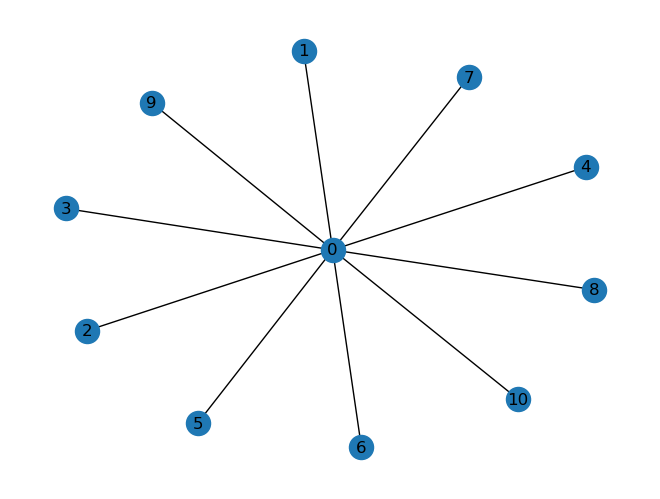

In [28]:
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)

In [52]:
# Task 1a

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[1:] = 0.05
assert np.allclose(sum(prediction), 1)

task_1a = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [53]:
# Task 1b

# Ground truth
true_node = 1

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[1:] = 0.05
assert np.allclose(sum(prediction), 1)

task_1b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [54]:
# Task 1c

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0
prediction[1:] = 0.1
assert np.allclose(sum(prediction), 1)

task_1c = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [55]:
# Task 1d

# Ground truth
true_node = 1

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0
prediction[1:] = 0.1
assert np.allclose(sum(prediction), 1)

task_1d = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [56]:
# Task 1e

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[1] = 0.5
assert np.allclose(sum(prediction), 1)

task_1e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [57]:
# Task 1f

# Ground truth
true_node = 1

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[1] = 0.5
assert np.allclose(sum(prediction), 1)

task_1f = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

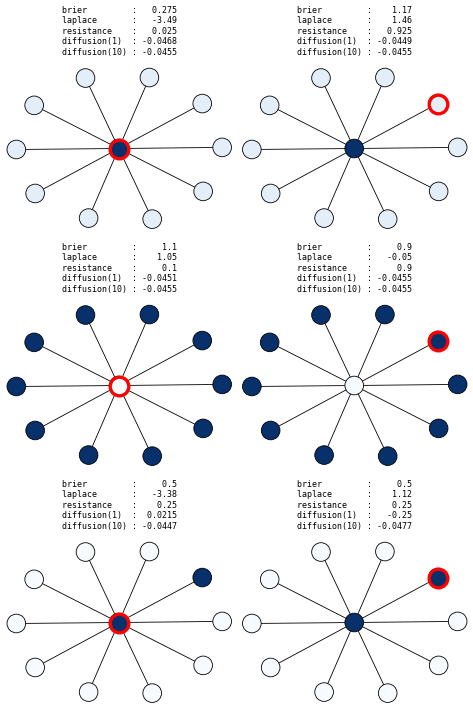

In [68]:
fig, axs = plt.subplots(3, 2, figsize=(8, 12), dpi=60)

for task, ax in zip([task_1a, task_1b, task_1c, task_1d, task_1e, task_1f], axs.flatten()):
    plot_task(
        ax, G, node_probs=task.node_probs, true_node=task.true_node, 
        labels=False, colorbar=False, contrast=1, prob_color="Blues", true_color="red", 
        scores=[
            "brier", 
            "laplace", 
            "resistance", 
            {"diffusion": {"kappa2": 1}}, 
            {"diffusion": {"kappa2": 10}}
        ], 
        score_pos="top"
    )
    ax.set_axis_off()  # optional, already done in plot_task

plt.tight_layout()
plt.show()

# Network models